# Prepare the environment

In [1]:
!pip install --upgrade pip
!pip install scikit-learn pandas

In [2]:
import pandas as pd

# Load the data and build some insights

In the following sections we are going to load the data and try to learn as much as possible from it. Thus, we are going to follow this steps:
 * Load the data
 * Train an initial classifier
 * Perform feature engineering
 * Train another classifier
 * Do some in-depth analysis
 * Ablation studies


### Load the data

In [3]:
train=pd.read_csv('data/train.csv')
valid=pd.read_csv('data/valid.csv')
test=pd.read_csv('data/test.csv')
train_valid=pd.read_csv('data/train_val.csv')
display(train)
display(valid)
display(test)

,Unnamed: 0,cmd,label
0,0,find /myfiles -atime +30,0
1,1,ln -sfn /other/dir new_dir,0
2,2,find . -name “*.old” -print | wc -l,0
3,3,find . -name “*.old” -print | xargs rm,0
4,4,"find / -name ""*gif"" -print",0
...,...,...,...
6645,6645,find tmp -maxdepth 1 -name *.mp3 -print0 | xar...,0
6646,6646,find . -type f -exec ls -s {} \; | sort -n -r,0
6647,6647,find /path -type f -exec chmod 644 {} +;,0
6648,6648,find . -name myfile |& grep -v 'Permission den...,0


,Unnamed: 0,cmd,label
0,0,find / -name document -print,0
1,1,"find . -name ""*.xml"" -exec grep -HFf <(find . ...",0
2,2,mkdir mnt point,0
3,3,"find . -name ""*.java""",0
4,4,"find . -name ""*sub*.cpp""",0
...,...,...,...
827,827,find . '(' -name FOLDER1 -prune -o -name filen...,0
828,828,who | wc -l,0
829,829,cat `which java` | file -,0
830,830,find . -newer CompareFile -print,0


,Unnamed: 0,cmd,label
0,0,read -r a,0
1,1,"find /etc -execdir echo ""{}"" ';'",0
2,2,sudo env,0
3,3,ssh -o UserKnownHostsFile=/dev/null username@h...,0
4,4,diff <(sort -n ruby.test) <(sort -n sort.test),0
...,...,...,...
825,825,find . -name '*.java',0
826,826,find $HOME -name '*.c' -print | xargs grep ...,0
827,827,"find ""$some_directory"" -type f -name '.*' -delete",0
828,828,find . -maxdepth 1 -type f ! -name '*.gz' -exe...,0


### Train an initial classifier and check the accuracy

We need a way to convert text into numerical features. While, there are many options out there, we are going to use a classical approach, called CountVectorizer

In [4]:
from sklearn.feature_extraction.text import CountVectorizer
train_x=train_valid['cmd']
train_y=train_valid['label']
test_x=test['cmd']
test_y=test['label']
test_x_text=train_x

# initialize the vectorizer and build the vectorization model
cv=CountVectorizer()
train_x=cv.fit_transform(train_x)
test_x=cv.transform(test_x)


from sklearn.tree import DecisionTreeClassifier # lets use a decission tree for explainability
classifier = DecisionTreeClassifier(random_state=1234)
classifier.fit(train_x, train_y)
from sklearn.metrics import f1_score, confusion_matrix
test_y_pred=classifier.predict(test_x)
print(f1_score(test_y, test_y_pred))
print(confusion_matrix(test_y, test_y_pred))

0.9577464788732394
[[756   2]
 [  4  68]]


In [5]:
for t_pred, t_real, cmd in zip (test_y_pred, test_y, test_x_text):
    if t_pred!=t_real:
        print(cmd, t_pred, t_real)

sudo find / -name "orm.properties" 1 0
find . -name aaa -print 0 1
find -name met* 0 1
joe
^K!/bin/sh 1 0
find / -mmin +90 0 1
sudo chown -Rf www-data * 0 1


### Insights into the data

Let's start by splitting our feature set into commands, keywords and paths. Using this feature set will not completely describe our dataset (e.g. there is no network information here), but it will allow us with out ablation study. Thus, we define the following helper functions:

- `extract_features` - this will extract features form the three categories (commands, paths and keywords)
- `posix_split_all` -  helper function to tokenize the input

In [7]:
LINUX_COMMANDS = ['cat', 'chmod', 'cp', 'curl','sqlite3','postgres','runuser','ldapsearch','adduser',
                  'export', 'ftp', 'history','ping','egrep','bzip',
                  'ifconfig', 'kill', 'last', 'mkdir',
                  'mv', 'passwd','lsof','nkf',
                  'ps', 'rm', 'sshd', 'tar','node',
                  'uname', 'unzip', 'nc', 'useradd',
                  'userdel', 'vi', 'vim', 'wget', 'whoami', 'sshd', 'w',
                  'socat', 'telnet', 'pip', 'easy_install',
                  'nmap', 'scp', 'sftp', 'smbclient', 'tftp', 'whois',
                  'finger', 'crontab', 'cpan', 'apt-get', 'byebug', 'cobc', 'cpulimit','rvim',
                  'ltrace', 'nohup', 'top', 'nice', 'netstat', 'find', 'pwd', 'ls',
                  'ssh', 'gdb', 'sudo', 'netdiscover', 'chroot', 'lsbrelease', 'cut',
                  'awk', 'gawk', 'chowm', 'chkconfig', 'selinux', 'visudo', 'runlevel',
                  'slapd', 'openssl', 'auditctl', 'usermod', 'groups', 'chgrp',
                  'cobc', 'emacs', 'journalctl', 'ltrace', 'rsync', 'strace', 'rvim',
                  'cpan', 'mkfifo', 'perl', 'lpstat', 'python', 'arp', 'php', 'ruby',
                  'node', 'jrunscript', 'ifconfig', 'tcpdump', 'echo', 'strings', 'mono',
                  'mknod', 'backpipe', 'tee', 'busybox', 'exec', 'route', 'emacs', 'rlogin',
                  'xxd', 'view', 'rpcclient', 'dnsdomainname', 'aria2c', 'mysql', 'debugfs',
                  'iptables', 'masscan', 'bash', 'tmux', 'screen', 'gcc', 'grep', 'for',
                  'while', 'gpg', 'hostname', 'sleep', 'dpkg', 'which', 'fstab', 'env', 'set',
                  'base64', 'sed', 'dd', 'ssh-keyscan', 'locate', 'unset', 'printenv', 'crash', 'miner', 'minerd','dirb',
                  'mount', 'ldconfig', 'lld', 'ftp', 'proxytunel', 'yum', 'mailcap', 'openvpn', 'valgrind', 'rpm',
                  'xargs', 'java', '/usr/bin/ssh', '/bin/ssh', './nc', './ncat', './socat', '/usr/bin/dpkg', 'postfix',
                  'ansible', 'git', 'docker', 'slsh', 'hexdump', 'ghc', 'chef', 'salt', 'showmount', 'zsh', 'go',
                  'chattr', 'sha1sum', 'syn.scan', 'modprobe', 'lsb-release','du','df','timeout','time','bzip','apt-key','chown','javac',
                  'more','ssldump','traceroute','ldapsearch','mtr','ntpdate','csvtool']
LINUX_PATHS = ['/dev/mem', '/dev/tcp', '/dev/udp', '/dev/kmem', '/dev/null', '/inet/tcp', '/bin/sh', '/inet/udp',
               '/etc/crontab', '/var/spool/cron', '/bin/bash', '/etc/passwd', '/etc/issue', '/etc/shadow',
               '/proc/version', '/etc/ssh/sshd_config', '/etc/services', '/etc/network/interfaces',
               '/etc/sysconfig/network', '/etc/resolv.conf', '/etc/fstab', '/etc/group', '/etc/hostname', '/etc/hosts',
               '/etc/inetd.conf', '/boot', '.ssh/', '/etc/fstab', '/etc/profile', '/bin/bash', '/tmp/bash',
               '/etc/sudoers','/etc/vncpasswd','/proc/','/var/tmp/','/dev/tty','/bin/ssh','/tmp/','csvtool',
               '/usr/bin/yum']
LINUX_KEYWORDS = ['pty', 'spawn', 'pty.spawn', 'password', 'shadow', 'passwd', 'username', 'pass', 'ctypes', 'cdll',
                  'LoadLibrary', 'fiddle', 'dlopen', 'http', 'install', 'ProxyCommand', 'null', 'lua', 'eval', 'os',
                  'exec', 'execute', 'function', '-i', '-e', '-p', '-t', '-r', '-R', '-L', '-l', '-c', '-C', '-n',
                  'fsockopen', 'socket', 'subprocess', '-nlvp', '-nvlp', '-pnlv', '-vlnp', '-lvnp', '-user', '-perm',
                  '-group', '-exec', 'shell', 'vim.command', 'os.execute', '-qc', '-sV', '-sC', '-O', '-T4', '-Pn',
                  '-p-', '-oA', '--list-keys', '+x', 'TCP-LISTEN', '-net', '-N', '-L', '-ivh', '-nx', '-ex', '777',
                  '677', '--allow-overwrite', '--on-download-complete', 'os.getppid', 'os.getpid', '-F', 'nfs', 'smb',
                  'sh', 'bash', '-b', 'sudoers', 'shell_exec', 'system', 'passthru', 'popen', 'proc_open', 'ztcp',
                  'bash_history', '-u', 'lsb-release','gpgsetup','createWriteStream','AF_INET','SOCK_STREAM','SOL_TCP','TCPSocket',
                  'kinsing','passwordauth']


def posix_split_all(s: str):
    try:
        import shlex
        text = s
        i_toks = [text]
        c_toks = list(shlex.shlex(text, punctuation_chars=True, posix=True))
        while c_toks != i_toks:
            i_toks = c_toks
            c_toks = []
            for tok in i_toks:
                tmp = list(shlex.shlex(tok, punctuation_chars=True, posix=True))
                for nt in tmp:
                    c_toks.append(nt)
        return c_toks
    except:
        return s.split()
                
def extract_features(cmd:str, flags=['COMMAND', 'KEYWORDS', 'PATH']):
    feats=[]
    toks=posix_split_all(cmd)
    if 'COMMAND' in flags:
        for command in LINUX_COMMANDS:
            if command in toks:
                feats.append(f'COMMAND:{command}')
    if 'KEYWORDS' in flags:
        for kw in LINUX_KEYWORDS:
            if kw in toks:
                feats.append(f'KEYWORD:{kw}')
    if 'PATH' in flags:
        for pth in LINUX_PATHS:
            if pth in cmd:
                feats.append(f'PATH:{pth}')
    return feats
    

<span style="color:red">**Comment:**</span> The `train_test` method is used to extract features, train a classifier and print the F1 score on the test set. This will enable us to test various feature combinations in the ablation studies.

In [8]:
def train_test(flags=['COMMAND', 'KEYWORDS','PATH']):
    train_x=train_valid['cmd']
    train_y=train_valid['label']
    test_x=test['cmd']
    test_y=test['label']
    test_x_text=train_x
    
    train_x_feats=[]
    for x in train_x:
        train_x_feats.append(' '.join(extract_features(x, flags)))
    test_x_feats=[]
    for x in test_x:
        test_x_feats.append(' '.join(extract_features(x, flags)))
    print(train_x_feats[:5])


    # initialize the vectorizer and build the vectorization model
    cv=CountVectorizer()
    train_x=cv.fit_transform(train_x_feats)
    test_x=cv.transform(test_x_feats)
    
    from sklearn.tree import DecisionTreeClassifier # lets use a decission tree for explainability
    classifier = DecisionTreeClassifier(random_state=1234)
    classifier.fit(train_x, train_y)
    from sklearn.metrics import f1_score, confusion_matrix
    test_y_pred=classifier.predict(test_x)
    print(f1_score(test_y, test_y_pred))
    print(confusion_matrix(test_y, test_y_pred))


<span style="color:red">**Comment:**</span> Let us first **have a baseline of our data**: what happens if we return malicious for all examples?

In [11]:
print(f1_score(test_y, [1 for _ in range (len(test_y))]))

0.15964523281596452


<span style="color:red">**Comment:**</span> Let's now test with the full feature set, to see where we landed with this feature schema. It will **work worse than the raw classifier** on this dummy dataset, but **this will not be the case with a real-life balanced set**.

In [12]:
train_test(['COMMAND', 'KEYWORDS','PATH'])

['COMMAND:find', 'COMMAND:rm COMMAND:find KEYWORD:-exec', 'KEYWORD:-t', 'COMMAND:find COMMAND:echo KEYWORD:-exec', 'COMMAND:echo']
0.8253968253968254
[[756   2]
 [ 20  52]]


<span style="color:red">**Comment:**</span> We are goint to test each feature set independently and check some combinations. This way we are going to better understand our data:

In [13]:
train_test(['COMMAND'])

['COMMAND:find', 'COMMAND:rm COMMAND:find', '', 'COMMAND:find COMMAND:echo', 'COMMAND:echo']
0.6956521739130435
[[755   3]
 [ 32  40]]


In [14]:
train_test(['PATH'])

['', '', '', '', '']
0.4842105263157895
[[758   0]
 [ 49  23]]


In [15]:
train_test(['KEYWORDS'])

['', 'KEYWORD:-exec', 'KEYWORD:-t', 'KEYWORD:-exec', '']
0.3956043956043956
[[757   1]
 [ 54  18]]


In [16]:
train_test(['COMMAND', 'KEYWORDS'])

['COMMAND:find', 'COMMAND:rm COMMAND:find KEYWORD:-exec', 'KEYWORD:-t', 'COMMAND:find COMMAND:echo KEYWORD:-exec', 'COMMAND:echo']
0.7130434782608696
[[756   2]
 [ 31  41]]


In [17]:
train_test(['COMMAND', 'PATH'])

['COMMAND:find', 'COMMAND:rm COMMAND:find', '', 'COMMAND:find COMMAND:echo', 'COMMAND:echo']
0.828125
[[755   3]
 [ 19  53]]


In [18]:
train_test(['KEYWORDS', 'PATH'])

['', 'KEYWORD:-exec', 'KEYWORD:-t', 'KEYWORD:-exec', '']
0.6428571428571429
[[754   4]
 [ 36  36]]


In [19]:
def plot_histo(flags=['COMMAND']):
    feat2val={}
    train_x=train_valid['cmd']
    train_y=train_valid['label']
    
    train_x_feats=[]
    for x, y in zip(train_x, train_y):
        feats=extract_features(x, flags)
        for feat in feats:
            if feat not in feat2val:
                feat2val[feat]={'feat': feat, 'malign': 0, 'benign':0}
            if y==0:
                feat2val[feat]['benign']+=1
            else:
                feat2val[feat]['malign']+=1
                
    def render(reverse=False):
        feats=[]
        malign=[]
        benign=[]
        f2v_sorted={k: v for k, v in sorted(feat2val.items(), key=lambda item: item[1]['benign'], reverse=reverse)}
        for feat in f2v_sorted:
            feats.append(feat)
            malign.append(feat2val[feat]['malign'])
            benign.append(feat2val[feat]['benign'])
        df_plot = pd.DataFrame(
        {'feats': feats[:20],
         'benign': benign[:20],
         'malign': malign[:20]
        })
    
        df_plot.plot(x="feats", y=["benign", "malign"], kind="bar")
        
    render(False)
    render(True)

    
    

<span style="color:red">**Comment:**</span> Lets dig a little dipper, to check the quality of our data

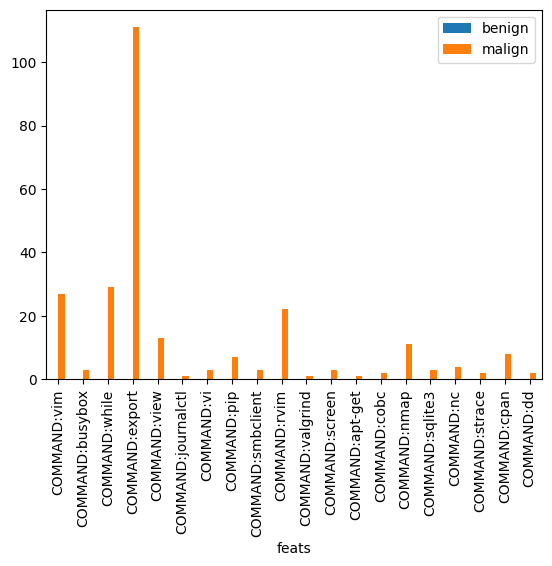

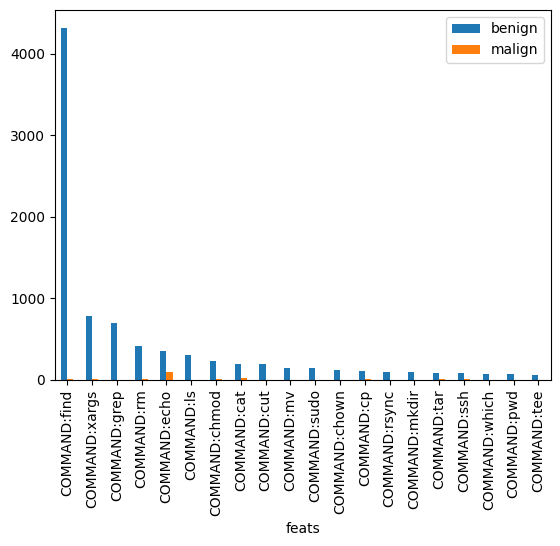

In [20]:
plot_histo(['COMMAND'])

<span style="color:red">**Exercise:**</span> Try your own experiments